# Superproton: six practical trajectory analyses

Learn to distinguish local motion from transport, estimate rates, and compare mechanisms using reusable `superproton` calls.

**Google Colab:** choose **Runtime → Run all**. The first cell downloads the code and example data and installs the dependencies. Use the default CPU runtime; no local installation is needed.

**Local Jupyter:** run all cells in order from this checkout, using a kernel with the scientific dependencies, including OVITO. Installing Superproton is optional; setup imports the local source. If Jupyter starts elsewhere, set `SUPERPROTON_ROOT` to the checkout path.

The bundled **75 ps** trajectories demonstrate execution. Saved outputs illustrate longer inputs; **Run all** replaces them with results from the selected trajectories. For longer inputs, copy `examples/tutorial-inputs.example.json` to `examples/tutorial-inputs.local.json` and edit its paths and temperatures. Set `SUPERPROTON_USE_LOCAL_INPUTS=0` to ignore that local configuration. The `MATERIAL` setting below selects CDP or CHS for sections 2–6; section 1 compares both.

| Section | What you learn | Paper context |
|---|---|---|
| 1 | Distinguish motions in proton traces; compare CDP/CHS pointing and subsequent transfer | 3a–e; S17a; S18, S20 |
| 2 | Fit residence distributions and estimate productive/nonproductive rates | 4a / 7a; S12; one temperature in 4b / 7c |
| 3 | Relate bound-proton coordination to rotation residence | 4d / 7b |
| 4 | Measure spatial/temporal event correlations | S8 / S9 |
| 5 | Measure rotation displacements and O–H reorientation | 3f / S21; 5b / 7d; S14–S16 |
| 6 | Map orientational preferences and vector relaxation | 8 |

Most configured lessons use up to the first **1.5 ns**; CDP rate fitting uses the **complete input**. For paper results, use the matching full source trajectories and the [figure-reproduction tools](https://github.com/mir-group/super_proton/blob/main/docs/paper_mapping.md).

Exact caches in `notebooks/cache` speed up repeat runs and survive kernel restarts; delete that folder to recompute. In Colab, files last only for the lifetime of the runtime.

Paths in tables and save messages are shown relative to the repository root where possible (`..` means a parent directory).

### Use your own trajectory

Adapt the trajectory path and atom mapping in each analysis call you reuse. Setup, tracking and pointing load mappings separately.

- Use LAMMPS text dumps with `id type xu yu zu`, coordinates in Å, persistent positive atom IDs and fixed types, uniform saved-frame spacing, and a fixed, fully periodic orthorhombic cell.
- Set `FRAME_TO_PS` to the interval between saved frames in ps. It is shared across the notebook's inputs. Frame bounds are zero-based source-frame indices; the end is exclusive.
- Mapping JSON fields are `hydrogen_type`, `oxygen_type` and `center_type`; the supplied values 2, 4 and 3 are examples. Default grouping assigns four oxygens to each center at frame zero. For other fixed groupings, supply `oxygen_parents` mapping every oxygen ID to its center ID.

Rerun from setup after changing inputs or settings; restart the kernel after changing package source.


In [ ]:
# @title Set up the environment and example data
from pathlib import Path
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    COLAB_ROOT = Path(os.environ.get("SUPERPROTON_ROOT", "/content/super_proton")).expanduser().resolve()
    if not COLAB_ROOT.exists():
        print("Downloading Superproton and the two 75 ps example trajectories...", flush=True)
        subprocess.check_call([
            "git", "clone", "--depth", "1", "--branch", "main",
            "https://github.com/mir-group/super_proton.git", str(COLAB_ROOT),
        ])
    required = ("pyproject.toml", "superproton/io.py",
                "data/cdp_525K_dump_1.trj", "data/chs_450K_dump_1.trj")
    if not all((COLAB_ROOT / name).is_file() for name in required):
        raise FileNotFoundError(
            f"{COLAB_ROOT} is not a complete Superproton checkout. "
            "Set SUPERPROTON_ROOT to a complete checkout or an unused download path."
        )
    # OVITO 3.16.1+ bundles the Linux libraries needed for analysis without a display.
    print("Installing the tutorial dependencies...", flush=True)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check",
        str(COLAB_ROOT), "ovito>=3.16.1,<4",
    ])
    os.environ["SUPERPROTON_ROOT"] = str(COLAB_ROOT)
    os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
    if (COLAB_ROOT / ".git").exists():
        revision = subprocess.check_output(
            ["git", "-C", str(COLAB_ROOT), "rev-parse", "--short", "HEAD"], text=True).strip()
        print(f"Ready: Superproton {revision}, with bundled CDP and CHS data.")
else:
    print("Local notebook: using your existing Python environment and checkout.")


In [1]:
%matplotlib inline
from pathlib import Path
import os
import json
from datetime import datetime
import sys

# Import directly from this checkout; installing Superproton is optional.
# For a kernel started elsewhere, set SUPERPROTON_ROOT to the checkout path.
SEARCH_FROM = Path(os.environ.get("SUPERPROTON_ROOT", Path.cwd())).expanduser().resolve()
ROOT = next((p for p in (SEARCH_FROM, *SEARCH_FROM.parents)
             if (p / "pyproject.toml").is_file()
             and (p / "superproton" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the Superproton checkout. Start Jupyter in the repository "
        "or its notebooks folder, or set os.environ['SUPERPROTON_ROOT'] "
        "to the repository path and rerun this cell."
    )
# Avoid mixing an already imported package with a different checkout.
loaded_package = sys.modules.get("superproton")
if loaded_package is not None and Path(loaded_package.__file__).resolve().parent != ROOT / "superproton":
    raise RuntimeError("Restart the kernel/runtime after switching Superproton checkouts.")
# Prefer the checkout over an installed copy. Restart the kernel after switching checkouts.
if str(ROOT) in sys.path:
    sys.path.remove(str(ROOT))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from superproton.io import AtomMapping
from superproton.workflow import Analysis
from superproton import residence, correlation, plots, tracking, io

def display_path(path):
    """Format paths relative to the repository without changing file access."""
    path = Path(path).resolve()
    try:
        return os.path.relpath(path, ROOT)
    except ValueError:  # Different drives on Windows cannot form a relative path.
        return str(path)


MATERIAL = os.environ.get("SUPERPROTON_MATERIAL", "CDP")
if MATERIAL not in {"CDP", "CHS"}:
    raise ValueError("SUPERPROTON_MATERIAL must be CDP or CHS")
DATA_DIR = Path(os.environ.get("SUPERPROTON_DATA", ROOT / "data"))
REFERENCE = ROOT / "data/reference"
LOCAL_CONFIG = Path(os.environ.get("SUPERPROTON_TUTORIAL_CONFIG", ROOT / "examples/tutorial-inputs.local.json"))
INPUTS = json.loads(LOCAL_CONFIG.read_text()) if LOCAL_CONFIG.is_file() and os.environ.get("SUPERPROTON_USE_LOCAL_INPUTS", "1") != "0" else {}
PRESET = INPUTS.get(MATERIAL, {})
DEMO_CDP = DATA_DIR / "cdp_525K_dump_1.trj"
DEMO_CHS = DATA_DIR / "chs_450K_dump_1.trj"
TRAJECTORY = Path(os.environ.get("SUPERPROTON_TRAJECTORY", PRESET.get("analysis", DEMO_CDP if MATERIAL == "CDP" else DEMO_CHS))).expanduser()
CDP_TRACKING = Path(INPUTS.get("CDP", {}).get("tracking", DEMO_CDP)).expanduser()
CHS_TRACKING = Path(INPUTS.get("CHS", {}).get("tracking", DEMO_CHS)).expanduser()
TRACKING_TEMPERATURES = {
    name: INPUTS.get(name, {}).get("tracking_temperature_K",
        None if "tracking" in INPUTS.get(name, {}) else demo_temperature)
    for name, demo_temperature in [("CDP", 525), ("CHS", 450)]
}
ORIENTATION_TRAJECTORY = Path(PRESET.get("orientation", TRAJECTORY)).expanduser()
for source in (TRAJECTORY, CDP_TRACKING, CHS_TRACKING, ORIENTATION_TRAJECTORY):
    if not source.is_file():
        raise FileNotFoundError(f"Configured trajectory is missing: {source}")
TEMPERATURE_K = PRESET.get("analysis_temperature_K", 525 if MATERIAL == "CDP" else 450)
ORIENTATION_TEMPERATURE_K = PRESET.get("orientation_temperature_K", TEMPERATURE_K)
MAPPING = AtomMapping.from_json(ROOT / "examples" / ("cdp-mapping.json" if MATERIAL == "CDP" else "chs-mapping.json"))
FRAME_TO_PS = 0.05  # saved-frame time, not the MD integration timestep
START_FRAME = int(os.environ.get("SUPERPROTON_START_FRAME", "200"))
DEMO_END_PS = 1500.0  # first 1.5 ns; first 10 ps excluded in event analyses
RATE_END_PS = None if MATERIAL == "CDP" else DEMO_END_PS  # full CDP run for its slower fitted rates
OVERALL_MODEL = "piecewise" if MATERIAL == "CDP" else "single"
GEOMETRY_DWELL_PS = 2.0 if MATERIAL == "CDP" else 10.0
ORIENTATION_INDEX = 23  # zero-based column of the sorted polyanion IDs
OUT = Path(os.environ.get("SUPERPROTON_OUTPUT", ROOT / "results" / f"tutorial-{MATERIAL}-{datetime.now():%Y%m%d-%H%M%S}"))
CACHE_DIR = ROOT / "notebooks/cache"  # reusable, compressed arrays; set None to disable
analysis = Analysis(TRAJECTORY, material=MAPPING, frame_to_ps=FRAME_TO_PS,
    start_frame=START_FRAME, cache_dir=CACHE_DIR, collect_coordination=True)
available_frames = analysis.pipeline.source.num_frames
if RATE_END_PS is not None:
    analysis.end_frame = min(available_frames, int(round(RATE_END_PS / FRAME_TO_PS)))
display(pd.DataFrame([
    {"purpose": "Rates; shared histories for later lessons", "source": display_path(TRAJECTORY), "temperature_K": TEMPERATURE_K},
    {"purpose": "Fig. 3c–e, H268", "source": display_path(CDP_TRACKING), "temperature_K": TRACKING_TEMPERATURES["CDP"]},
    {"purpose": "S17a, H342", "source": display_path(CHS_TRACKING), "temperature_K": TRACKING_TEMPERATURES["CHS"]},
    {"purpose": "Fig. 8", "source": display_path(ORIENTATION_TRAJECTORY), "temperature_K": ORIENTATION_TEMPERATURE_K},
]))
print("Rate-analysis source frames:", analysis.window, "Available:", available_frames, "Output:", display_path(OUT))


,purpose,source,temperature_K
0,Rates; shared histories for later lessons,../../MLMD/H_525K_4ns/dump_1.trj,525
1,"Fig. 3c–e, H268",../../MLMD/H_525K_1.5ns/dump_1.trj,525
2,"S17a, H342",../../MLMD/CHS/H_500K_1.5ns/dump_1.trj,500
3,Fig. 8,../../MLMD/H_550K_4ns/dump_1.trj,550


Rate-analysis source frames: {'start_frame': 200, 'end_frame': None, 'stride': 1} Available: 80001 Output: results/tutorial-CDP-20261115-210444


## 1. Distinguish rattling, rotation, and productive rotation

**Figure 3a–e.** Follow a proton's nearest oxygen and that oxygen's parent polyanion. O1, O2, P1, P2 below are **first-encounter labels**, not atom IDs.

| Motion | How it appears in the tracked histories | Interpretation |
|---|---|---|
| Rattling | Donor switches back and forth within the same O pair | Local proton motion, without leaving that pair |
| Rotation | The local O-pair environment changes | Detect a third oxygen to delimit O-pair residence intervals |
| Productive rotation | The polyanion pair changes to include a third host | A carrier-assisted transfer to a new polyanion pair |

An O-pair change that keeps the same polyanion pair is a **nonproductive rotation**. The O and polyanion pair histories are segmented independently.

![Figure 3a–b: nonproductive and productive rotation](https://raw.githubusercontent.com/mir-group/super_proton/main/notebooks/assets/figure-3ab.png)

*Figure 3a–b, cropped from the [paper](https://doi.org/10.1021/jacs.5c21965). (a) An exchanger changes the available oxygen while the proton remains between the same polyanions. (b) A proton-bearing carrier rotates and transfers the proton from the provider toward a new recipient. The plots below are calculated from trajectories.*

### Read a CDP proton trace: Figure 3c–e

The paper's example uses **atom ID 268**, CDP **525 K**, and the **1.5 ns** trajectory. Track frames 0–19999 at 0.05 ps/frame, then display 450–820 ps. Starting analysis at 450 ps would reset encounter labels and the displacement reference.

The panels show displacement from frame zero, nearest O label, residence bands, and parent P label. Red dashed lines mark productive pair switches; red shading marks preceding rotation periods. Blue/orange bands show O–O/P–P residence intervals, including incomplete boundary intervals for display only.


,species,label,atom_id
0,O,1,643
1,O,2,868
2,O,3,893
3,O,4,644
4,O,5,894


,kind,source_frame,time_ps
0,O_pair_switch,2850,142.50
1,O_pair_switch,3104,155.20
2,O_pair_switch,10229,511.45
3,O_pair_switch,10255,512.75
4,O_pair_switch,11242,562.10


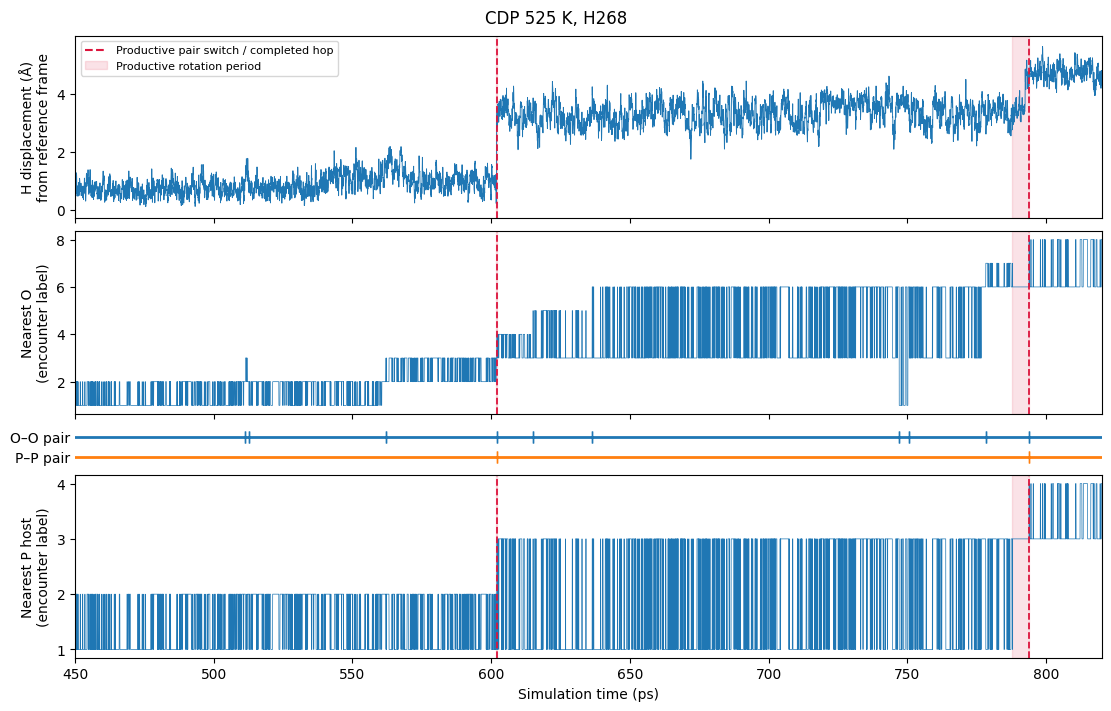

In [2]:
cdp_trace = tracking.candidate_trace(
    io.validated_pipeline(CDP_TRACKING), material=AtomMapping.from_json(ROOT / "examples/cdp-mapping.json"),
    proton_id=268, frame_to_ps=FRAME_TO_PS, start_frame=0, end_frame=20000)
cdp_window = (450, 820) if cdp_trace.track.t_ps.max() >= 820 else None
cdp_temperature = (f"{TRACKING_TEMPERATURES['CDP']} K"
    if TRACKING_TEMPERATURES["CDP"] is not None else "temperature unspecified")
fig_cdp_tracking = plots.candidate_tracking(cdp_trace, material="CDP", time_range=cdp_window,
    title=f"CDP {cdp_temperature}, H268"
    + (" — short-input demonstration" if cdp_window is None else ""))
display(cdp_trace.labels.head(), cdp_trace.events.head())
plt.show()

**Read the matched trace:** repeated O1/O2 changes show rattling; O-pair changes within the same P pair identify nonproductive rotations. In the paper's selected trajectory, productive switches at **602.10 and 793.85 ps** accompany larger displacements and a new polyanion.

**Reuse:** change `proton_id`, atom mapping, and trajectory. `trace.labels` maps encounter labels to atom IDs; `trace.events` gives event times. Displacement is measured from frame zero, not accumulated path length. The tables show previews; full results are exported.

### CHS: motion before the completed hop — Figure S17a

The paper's example uses **atom ID 342**, CHS **500 K**, the **1.5 ns** run, and a **280–500 ps** display window. Look for increasing displacement while the nearest oxygen/host label stays fixed in the shaded period, before the dashed S-pair switch. This illustrates CHS's longer pre-transfer delay. The bundled CHS file is a 450 K demonstration.


,kind,source_frame,time_ps
0,O_pair_switch,250,12.50
1,O_pair_switch,502,25.10
2,O_pair_switch,621,31.05
3,O_pair_switch,1071,53.55
4,O_pair_switch,1246,62.30


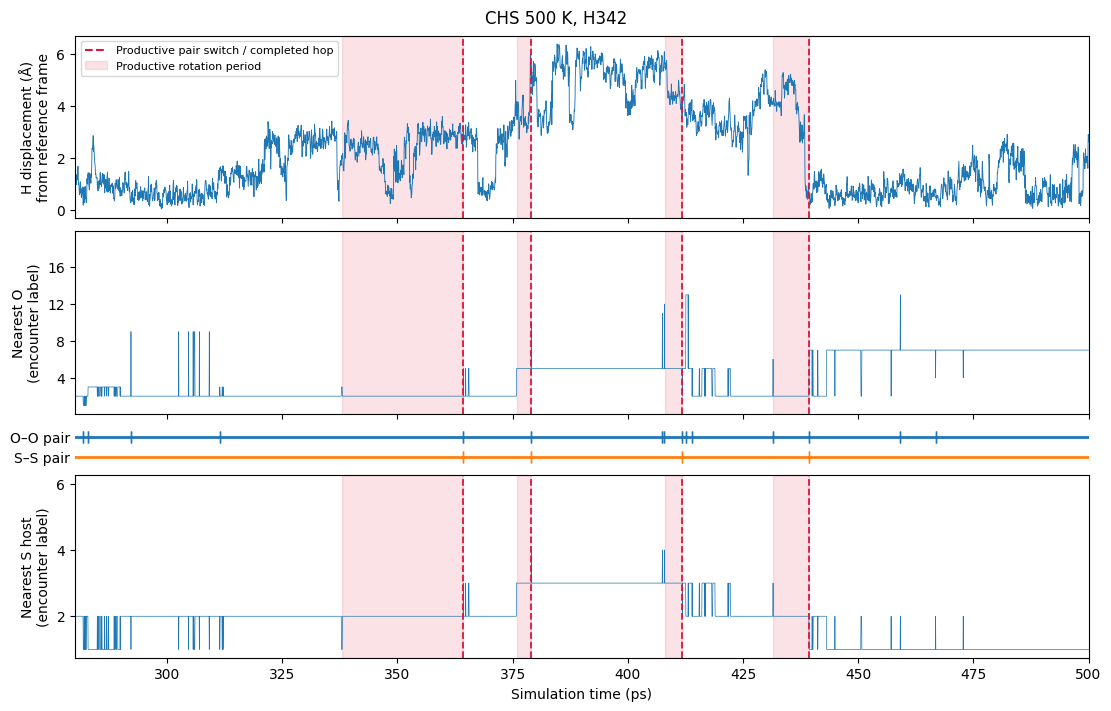

In [3]:
chs_trace = tracking.candidate_trace(
    io.validated_pipeline(CHS_TRACKING), material=AtomMapping.from_json(ROOT / "examples/chs-mapping.json"),
    proton_id=342, frame_to_ps=FRAME_TO_PS, start_frame=0, end_frame=20000)
chs_window = (280, 500) if chs_trace.track.t_ps.max() >= 500 else None
chs_temperature = (f"{TRACKING_TEMPERATURES['CHS']} K"
    if TRACKING_TEMPERATURES["CHS"] is not None else "temperature unspecified")
fig_chs_tracking = plots.candidate_tracking(chs_trace, material="CHS", time_range=chs_window,
    title=f"CHS {chs_temperature}, H342"
    + (" — short-input demonstration" if chs_window is None else ""))
display(chs_trace.events.head())
plt.show()

### Does pointing predict transfer? Compare CDP and CHS

**Does orienting toward a neighbor reliably lead to a hop?** Follow the covalent donor and hydrogen-bond acceptor for every proton. A new polyanion pair marks a pointing episode; rattling within the same pair does not. “Fresh” episodes exclude returns toward the previously vacated host.

| Outcome | What happens during an attempt |
|---|---|
| `committed` | The proton transfers to the pointed-at polyanion |
| `reverted` | The previous polyanion pair is restored first |
| `superseded` | Another target takes over first |
| `censored` | The trajectory ends before the outcome is known |

The configured comparison uses both materials at **550 K**, first **1.5 ns**, excluding 10 ps. Set `POINTING_END_PS = None` for full inputs. The bundled 75 ps files have different temperatures and demonstrate execution only. Actual inputs and windows are printed below.

`pointing()` follows donor/acceptor histories at every saved frame. Its hysteresis rule forms an H···O connection at **1.8 Å** and retains it until **2.4 Å**.


In [4]:
# Change paths AND their temperatures in the local JSON, or in both dictionaries below.
POINTING_SOURCES = {
    "CDP": Path(INPUTS.get("CDP", {}).get("pointing", DEMO_CDP)).expanduser(),
    "CHS": Path(INPUTS.get("CHS", {}).get("pointing", DEMO_CHS)).expanduser(),
}
POINTING_TEMPERATURES = {
    name: INPUTS.get(name, {}).get("pointing_temperature_K",
        None if "pointing" in INPUTS.get(name, {}) else demo_temperature)
    for name, demo_temperature in [("CDP", 525), ("CHS", 450)]
}
POINTING_END_PS = DEMO_END_PS  # quick example; None uses the full inputs
D_FORM_A, D_BREAK_A = 1.8, 2.4
LOOKAHEAD_PS = [0, 2, 5, 10, 25, 50, 100, 150]
pointing_analyses, pointing_inputs = {}, {}
for name, path in POINTING_SOURCES.items():
    mapping = AtomMapping.from_json(ROOT / "examples" / f"{name.lower()}-mapping.json")
    a = Analysis(path, material=mapping, frame_to_ps=FRAME_TO_PS,
                 start_frame=START_FRAME, cache_dir=CACHE_DIR)
    available = a.pipeline.source.num_frames
    if POINTING_END_PS is not None:
        a.end_frame = min(available, int(round(POINTING_END_PS / FRAME_TO_PS)))
    stop = available if a.end_frame is None else a.end_frame
    if stop <= START_FRAME:
        raise ValueError(f"{name}: analysis window contains no frames")
    pointing_analyses[name] = a
    pointing_inputs[name] = dict(path=str(path.resolve()), temperature_K=POINTING_TEMPERATURES[name],
        start_frame=START_FRAME, end_frame=stop, frame_to_ps=FRAME_TO_PS,
        start_ps=START_FRAME * FRAME_TO_PS, end_ps=stop * FRAME_TO_PS,
        analyzed_ps=(stop - START_FRAME) * FRAME_TO_PS)
pointing_table = pd.DataFrame(pointing_inputs).T
pointing_table["path"] = pointing_table["path"].map(display_path)
display(pointing_table)
# A 75 ps demo cannot support the 150 ps follow-up. Show outcomes only in that case.
pointing_lookahead = LOOKAHEAD_PS if min(v["analyzed_ps"] for v in pointing_inputs.values()) >= max(LOOKAHEAD_PS) else None
if pointing_lookahead is None:
    print("Short-input demonstration: follow-up panel omitted; use longer runs for the mechanism comparison.")

,path,temperature_K,start_frame,end_frame,frame_to_ps,start_ps,end_ps,analyzed_ps
CDP,../../MLMD/H_550K_4ns/dump_1.trj,550,200,30000,0.05,10.0,1500.0,1490.0
CHS,../../MLMD/CHS/H_550K_4ns/dump_1.trj,550,200,30000,0.05,10.0,1500.0,1490.0


**Ask two questions of the same histories.**

1. **Does the attempt complete a hop?** The bars count fresh, decided attempts; unresolved final attempts are excluded and reported separately.
2. **Does the pointed-at group receive the proton later?** The curves search during each fresh pair episode and for the specified additional time **after that episode ends**, allowing subsequent attempts. All fresh episodes enter this denominator, including terminally censored episodes. The available trajectory limits follow-up near its end.

The second panel measures subsequent arrival at the target; its x-axis is not time since pointing began, and the curve is not a waiting-time distribution. These complementary definitions correspond to SI Figures S18 and S20.

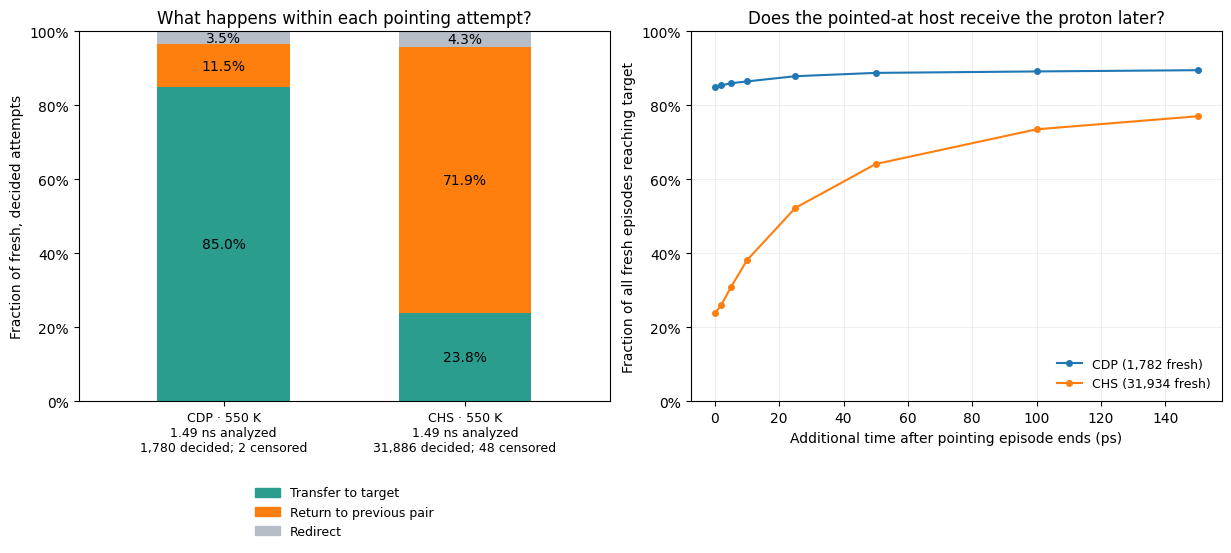

count  fraction_decided
material outcome                            
CDP      committed    1513          0.850000
         reverted      204          0.114607
         superseded     63          0.035393
         censored        2               NaN
CHS      committed    7579          0.237691
         reverted    22927          0.719030
         superseded   1380          0.043279
         censored       48               NaN

In [5]:
pointing = {
    name: a.pointing(d_form=D_FORM_A, d_break=D_BREAK_A, lookahead_ps=pointing_lookahead)
    for name, a in pointing_analyses.items()
}
pointing_labels = {
    name: (f"{name} · " + (f"{info['temperature_K']} K" if info["temperature_K"] is not None else "temperature unspecified")
           + f"\n{info['analyzed_ps'] / 1000:.3g} ns analyzed")
    for name, info in pointing_inputs.items()
}
fig_pointing = plots.pointing_comparison(pointing, labels=pointing_labels)
plt.show()
display(pd.concat({name: result["summary"].set_index("outcome")
                   for name, result in pointing.items()}, names=["material", "outcome"]))

**Read the comparison:** at matched 550 K, most CDP attempts complete a hop, whereas most CHS attempts return to the previous pair. CHS shows a larger increase when later arrival is allowed: pointing less reliably predicts transfer within the same attempt, but often identifies a group that receives the proton later. Check the calculated counts and input windows; the short demos do not establish this comparison.

**Inspect and reuse:** each attempt records persistent proton/donor/target IDs and onset/outcome times. `delay_ps` is onset-to-hop time for successful attempts; missing values are not zero-time hops. For another material, replace the inputs and `AtomMapping`, set the saved-frame interval, and justify the 1.8/2.4 Å thresholds from its hydrogen-bond geometry. Oxygen-to-polyanion membership must remain fixed.


In [6]:
# First five fresh attempts per material, in table order (not selected for success).
columns = ["proton_id", "donor_id", "target_id", "start_ps", "outcome", "outcome_ps", "delay_ps"]
display(pd.concat({name: r["attempts"].loc[r["attempts"].fresh, columns].head(5)
                   for name, r in pointing.items()}, names=["material", "row"]))

proton_id  donor_id  target_id  start_ps     outcome  \
material row                                                         
CDP      0          251       226        231     10.00   committed   
         1          251       226        227    182.95   committed   
         2          251       226        231    224.15   committed   
         3          251       231        232    463.80   committed   
         4          251       231        206    629.50   committed   
CHS      0          193       397        529     10.15  superseded   
         1          193       397        541     10.65    reverted   
         2          193       397        529     32.10   committed   
         3          193       397        541     70.35    reverted   
         5          193       397        541     71.40    reverted   

              outcome_ps  delay_ps  
material row                        
CDP      0         10.65      0.65  
         1        184.50      1.55  
         2        224.30      0.15  
         3        467.35      3.55  
         4        630.00      0.50  
CHS      0         10.65       NaN  
         1         32.10       NaN  
         2         44.15     12.05  
         3         71.10       NaN  
         5         72.25       NaN

## 2. Measure rotation rates: Figures 4a / 7a and S12

Fit general O-pair and productive polyanion-pair residence times. CDP uses a piecewise fit; CHS uses a single-rate fit. Two-rate components do not represent productive versus nonproductive populations.

The second panel follows **S12**: count nonproductive switches between productive switches, then fit a geometric distribution using intervals with N ≥ 2 and bins observed at least ten times. Raw counts remain available; the retained tail's slope gives probability p. Under the Bernoulli model, λNP = λP(1−p)/p. This assumption does not establish statistical independence.

The first `analysis.events` call retains tracks and strict bound-proton counts. `analysis.residence` collects complete intervals; `demo_analysis` shares the first 1.5 ns and excludes newly incomplete intervals at its endpoint.


,quantity,value,method,status,detail
0,overall,0.018295,direct_count_per_ps,complete,
1,productive,0.002349,direct_count_per_ps,complete,
2,nonproductive,0.015946,direct_count_per_ps,complete,
3,productive,0.002024,fit_per_ps,complete,
4,overall_fast,0.047331,fit_per_ps,complete,
5,overall_slow,0.006430,fit_per_ps,complete,
6,transition,72.031584,fit_ps,complete,
7,productive_probability,0.100331,geometric_fit,complete,
8,nonproductive,0.018153,model_per_ps,complete,


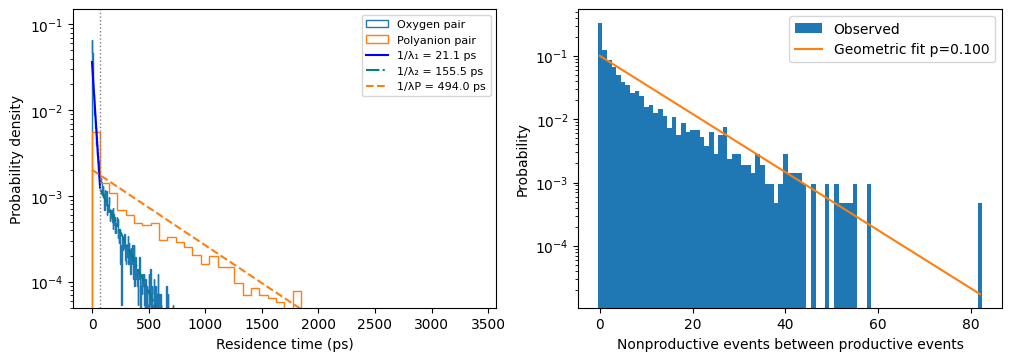

In [7]:
events = analysis.events  # one shared tracking/bond-count pass on the first run
samples = analysis.residence
rates = residence.rate_summary(events, overall_model=OVERALL_MODEL)
nonproductive_counts = residence.nonproductive_counts(events)
try:
    probability = residence.fit_productive_probability(nonproductive_counts)
except ValueError as exc:
    probability = None
    print("Geometric fit unavailable:", exc)
fig_rates = plots.residence_distributions(samples, counts=nonproductive_counts,
    probability=probability, overall_model=OVERALL_MODEL)
display(rates)
plt.show()
# Reuse the first 1.5 ns in later lessons; this slices arrays, not the trajectory file.
demo_end_frame = min(int(round(DEMO_END_PS / FRAME_TO_PS)), int(analysis.tracks.frame_indices[-1]) + 1)
demo_analysis = analysis.prefix(demo_end_frame)

CDP retains its full input because its productive-rate fit is sensitive to window length. CHS uses the first 1.5 ns for this demonstration. A successful fit (`status="complete"`) does not establish convergence.

An Arrhenius plot and activation energy require repeating the workflow at multiple temperatures and calling `residence.arrhenius_fit`.


## 3. Coordination versus rotation: Figure 4d / 7b

Does bound-proton population correlate with rotation residence? For each complete O-pair interval, select the polyanion less frequently occupied by the tracked proton, then average its strict mutual O–H bond count over that interval.

Reuse the first 1.5 ns of saved counts. The **40 × 24 bins** change display resolution, not bond counting or event detection. CDP's conditional means use the crossover from the longer rate fit.


,proton_id,residence_ps,mean_bound_protons
0,251,10.35,1.758454
1,251,30.80,1.746753
2,251,3.60,1.750000
3,251,2.85,1.789474
4,251,3.60,1.722222


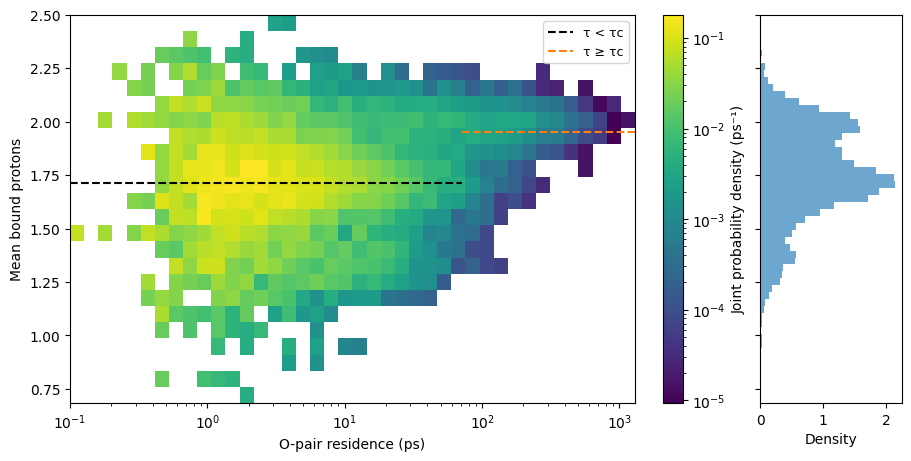

In [8]:
coordination = demo_analysis.coordination  # reuse stored counts; no second frame pass
transition = rates.loc[(rates.quantity == "transition") & (rates.status == "complete"), "value"]
fig_coordination = plots.coordination_distribution(coordination,
    transition_ps=float(transition.iloc[0]) if len(transition) else None, tau_bins=40, np_bins=24)
display(coordination.head())
plt.show()

**Read the plot:** in CDP, shorter residence intervals are associated with fewer bound protons on the selected group; sparse tails need more sampling. This association alone does not establish causation.

For your own data, set `collect_coordination=True` and call `analysis.coordination`. Figure 4c illustrates the neighbor definition.


## 4. Event correlations: Figures S8 / S9

Locate productive events at their recipient polyanions and compare observed pair counts with the paper's rate/site-density baseline. G_event > 1 indicates excess pairs relative to that baseline; G_event < 1 indicates fewer. The baseline rate uses the span from the first to last included event.

Plot the event-pair map and first three neighbor shells over up to 200 ps. The color range is 0–2; values outside it remain in the exported array. NP–P interval overlap (Tables S2–S3) is calculated and exported separately; low overlap alone does not establish independence.


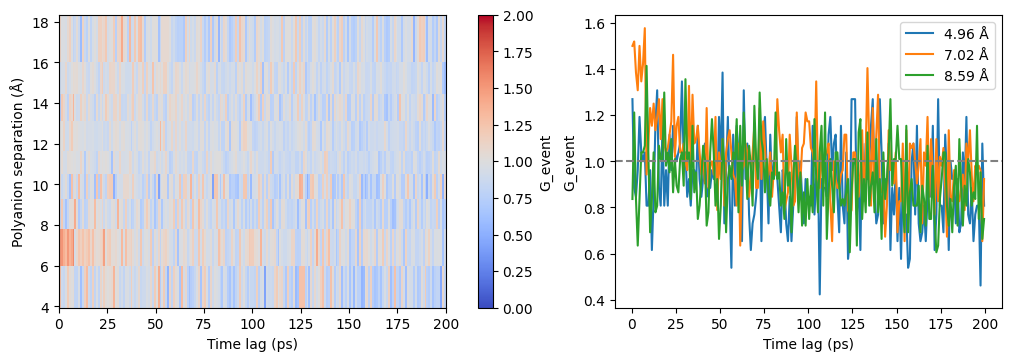

In [9]:
CORRELATION_LAG_PS = min(200, (demo_analysis.tracks.n_frames - 1) * demo_analysis.tracks.frame_to_ps)
event_correlation = demo_analysis.correlations(dt_max_ps=CORRELATION_LAG_PS, dt_bin_ps=1, r_max_A=20)
overlap = correlation.temporal_overlap(demo_analysis.events, tracking.parent_polyanions(demo_analysis.pipeline, MAPPING))
fig_correlation = plots.event_correlations(event_correlation)
plt.show()

Shorter windows contain fewer event pairs and give noisier correlations. Very short inputs also limit the available lag range.


## 5. Rotation distances and O–H reorientation: Figures 3f, 5b and S14–S16/S21

Compare oxygen displacement by role: nonproductive host/exchanger and productive carrier/recipient/provider (**3f / S21**), alongside proton displacement (**S14**). The geometry table gives linear/bent rigid-lever estimates from measured X–O–H geometry. Distances are in Å, not rotation angles.


,geometry,lever_A,oxygen_displacement_A,predicted_proton_displacement_A,measured_hop_A,excess_A
0,linear,2.640391,1.566168,2.571076,3.138155,0.567080
1,measured_bent,2.253119,1.566168,2.193970,3.138155,0.944186


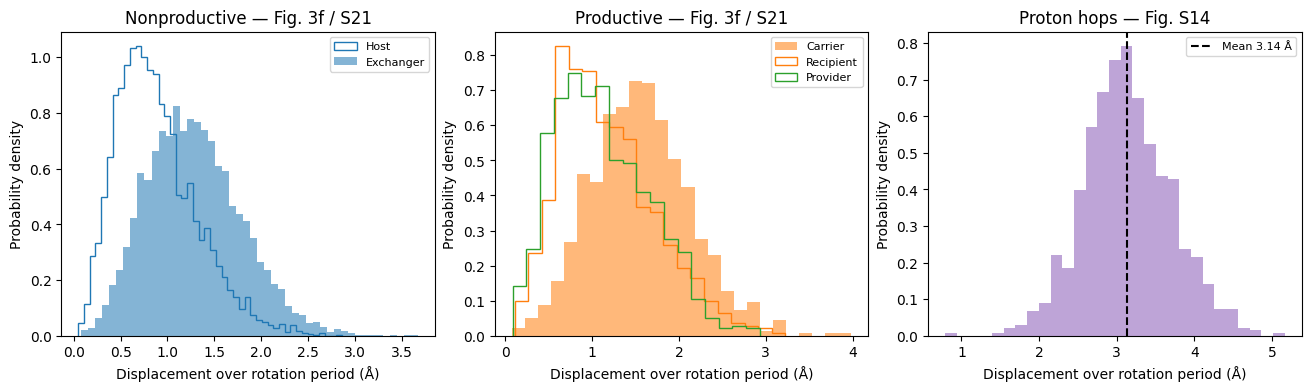

In [10]:
displacement = demo_analysis.displacements(dwell_ps=GEOMETRY_DWELL_PS)
fig_distances = plots.rotation_distances(displacement)
display(displacement["rigid"])
plt.show()

### Separate the outlier populations: Figure 5b / 7d

The baseline is each event's mean instantaneous dH/dO, pooled across event types. Each event's outlier metric averages instants above its mean plus two standard deviations. **Productive and nonproductive outliers remain separate.** Archived bin edges aid visual comparison; counts are newly calculated. Exported metrics include the tail beyond the displayed 97th percentile.


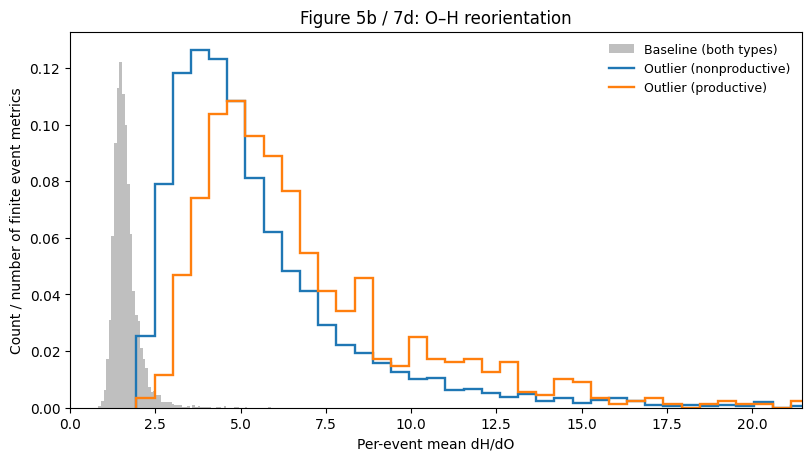

In [11]:
ratio_bins = pd.read_csv(REFERENCE / f"dhdo_ratio/{MATERIAL}_{525 if MATERIAL == 'CDP' else 450}K_dHdO_ratio.csv")
fig_reorientation = plots.reorientation_distributions(displacement["event_metrics"], reference_bins=ratio_bins)
plt.show()

### Inspect an event and its directions: Figures S15 / S16

The left panel shows the longest sampled event's ratio trace, baseline and outlier means (**S15-style**). The right uses up to 49 increments before productive transfer, stopping at a donor change and excluding the transfer increment (**S16**). Pre-transfer directions and full-period event means use different windows.

Evaluate the displacement gap and O–H reorientation together; an isolated large ratio is insufficient to identify a slingshot mechanism.


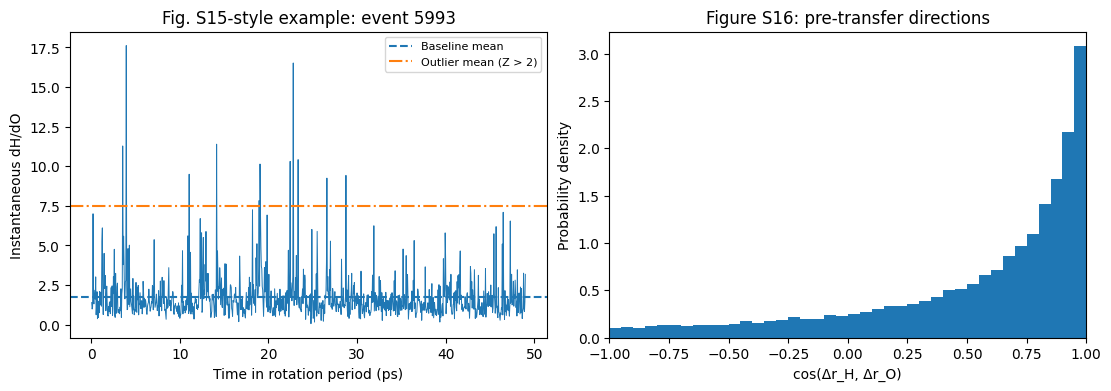

In [12]:
fig_reorientation_detail = plots.reorientation_detail(displacement)
plt.show()

## 6. Orientational landscapes and relaxation: Figure 8

Which directions do polyanions prefer, and how quickly does orientation decorrelate? Track one fixed X–O bond per polyanion and pool their angular samples. CHS uses the paper's fixed sublattice mapping; another structure requires checking its symmetry and axes.

Use the first **1.5 ns** of the configured **550 K** inputs, sampled every **0.5 ps** with **10° bins**. This stride applies only to orientation; proton-event analyses retain every 0.05 ps saved frame.

The pooled map accompanies a vector autocorrelation through at most 300 ps, excluding the first 10 ps and using 2.5 ps lag spacing. `include_single=True` adds one bond's map, which is incompletely sampled at 1.5 ns.

Red markers are experimental directions. Density is per degree², not per solid angle or a free energy.


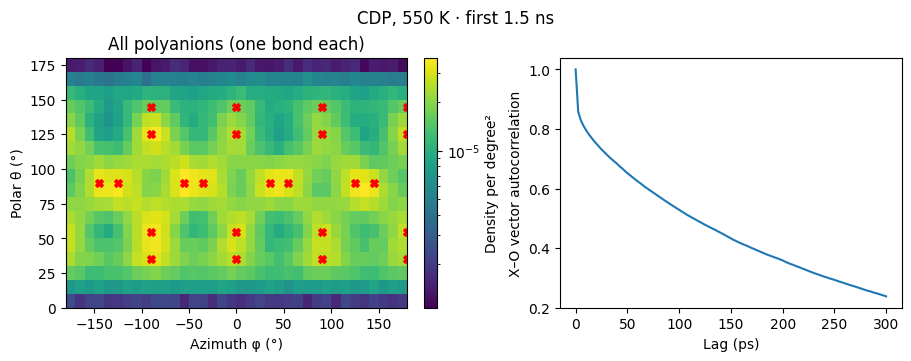

In [13]:
ORIENTATION_STRIDE = 10  # 10 saved frames = 0.5 ps; orientation only
ORIENTATION_LAG_PS = 300
ORIENTATION_LAG_STEP_PS = 2.5
orientation_analysis = Analysis(ORIENTATION_TRAJECTORY, material=MAPPING, frame_to_ps=FRAME_TO_PS,
    start_frame=0, stride=ORIENTATION_STRIDE)
orientation_analysis.end_frame = min(int(round(DEMO_END_PS / FRAME_TO_PS)), orientation_analysis.pipeline.source.num_frames)
orientation_dt = FRAME_TO_PS * ORIENTATION_STRIDE
vcf_start_sample = int(round(10.0 / orientation_dt))  # exclude 10 ps, not 200 subsampled frames
angular_bins = (np.arange(-180, 181, 10), np.arange(0, 181, 10))
experimental_sites = pd.read_csv(REFERENCE / f"orientation/{MATERIAL}_experimental_sites.csv").to_numpy()
orientation = orientation_analysis.orientations(align_chs=MATERIAL == "CHS", single_index=ORIENTATION_INDEX,
    map_bins=angular_bins, max_lag_ps=ORIENTATION_LAG_PS, lag_step_ps=ORIENTATION_LAG_STEP_PS,
    experimental_sites=experimental_sites, vcf_sample_slice=slice(vcf_start_sample, None))
fig_orientation = plots.orientations(orientation, include_single=False)  # True adds one bond's sampled map
fig_orientation.suptitle(f"{MATERIAL}, {ORIENTATION_TEMPERATURE_K} K · first {orientation_analysis.end_frame * FRAME_TO_PS / 1000:g} ns")
plt.show()

## Save results and reuse the analysis

Export tables, arrays, candidate traces, atom-ID mappings and figures. Settings record each input, analysis window and threshold. Setup chooses a timestamped folder; explicit nonempty destinations are rejected.


In Colab, find the saved folder under `super_proton/results` in the **Files** panel and download the results you want to keep before the runtime is deleted.

In [14]:
results = dict(cdp_candidate=cdp_trace, chs_candidate=chs_trace,
    pointing=pointing, residence=samples, rates=rates,
    nonproductive_counts=nonproductive_counts, coordination=coordination, correlation=event_correlation,
    overlap=overlap, displacement=displacement, orientation=orientation)
analysis.export(OUT, results, settings=dict(overall_model=OVERALL_MODEL, temperature_K=TEMPERATURE_K,
    demo_window=demo_analysis.window, collect_coordination=True, coordination_bins=[40, 24],
    geometry_dwell_ps=GEOMETRY_DWELL_PS, geometric_min_nonproductive=2, geometric_min_bin_count=10,
    direction_preceding_frames=50, pointing_d_form_A=D_FORM_A, pointing_d_break_A=D_BREAK_A,
    pointing_lookahead_ps=pointing_lookahead, pointing_inputs=pointing_inputs,
    correlation_dt_max_ps=CORRELATION_LAG_PS, correlation_dt_bin_ps=1, correlation_r_max_A=20, correlation_rate_policy="event_span",
    cdp_tracking_path=str(CDP_TRACKING), chs_tracking_path=str(CHS_TRACKING), tracking_end_frame=20000,
    cdp_proton_id=268, chs_proton_id=342, tracking_temperatures_K=TRACKING_TEMPERATURES, displacement_reference_frame=0,
    orientation_path=str(ORIENTATION_TRAJECTORY), orientation_temperature_K=ORIENTATION_TEMPERATURE_K,
    orientation_start_frame=0, orientation_end_frame=orientation_analysis.end_frame, orientation_stride=ORIENTATION_STRIDE,
    orientation_bin_degrees=10, orientation_index=ORIENTATION_INDEX,
    orientation_max_lag_ps=ORIENTATION_LAG_PS, orientation_lag_step_ps=ORIENTATION_LAG_STEP_PS,
    vcf_start_sample=vcf_start_sample, vcf_end_sample=None, vcf_sample_stride=1, align_chs=MATERIAL == "CHS"))
figures = {"tracking-CDP": fig_cdp_tracking, "tracking-CHS": fig_chs_tracking, "pointing-comparison": fig_pointing,
    "rates": fig_rates, "coordination": fig_coordination, "correlation": fig_correlation,
    "distances": fig_distances, "reorientation": fig_reorientation,
    "reorientation-detail": fig_reorientation_detail, "orientation": fig_orientation}
for name, fig in figures.items(): fig.savefig(OUT / f"{name}.png", dpi=150)
print("Saved:", display_path(OUT))
print("Method citation: https://doi.org/10.1021/jacs.5c21965")

Saved: results/tutorial-CDP-20261115-210444
Method citation: https://doi.org/10.1021/jacs.5c21965
